<div align="center">

<h1> <b> MOVIMIENTO DE UN SÓLIDO RÍGIDO EN UN FLUIDO: MODELADO Y SIMULACIÓN DEL EFECTO MAGNUS EN PELOTAS DE FÚTBOL </b> </h1>

</div>

<br>

<hr size=10 noshade color="green">
<p>
<p><img alt="UdeA logo" height="180px" src="https://upload.wikimedia.org/wikipedia/commons/archive/f/fb/20161010213812%21Escudo-UdeA.svg" align="left" hspace="100px" vspace="4px"></p>

<div align="right">       

<h3><i> <b>Cristian Vergara Restrepo <br>
Bernardo Mendoza Montes</b> <br>  
Universidad de Antioquia <br>
Instituto de Física  
</i></h3>
</div>

---


## Planteamiento del problema

El estudio del movimiento de sólidos rígidos constituye uno de los pilares fundamentales de la mecánica clásica. En su formulación más simple, el movimiento de un sólido puede describirse mediante la formulación lagrangiana, estudiando por separado la traslación y la rotación del cuerpo. Sin embargo, cuando un sólido se desplaza dentro de un fluido, su dinámica se vuelve considerablemente más compleja debido a la interacción con el medio.

Un caso particularmente interesante de esta interacción es el de un sólido rígido en rotación que se mueve a través de un fluido. En estas condiciones aparece una fuerza lateral, perpendicular a la velocidad de traslación, conocida como fuerza de Magnus. Este fenómeno es responsable de trayectorias curvas en numerosos sistemas físicos y desempeña un papel central en el comportamiento de objetos cotidianos como los balones de fútbol.

## Objetivos

* Modelar la dinámica de un balón de fútbol en un fluido.
* Usar métodos computacionales para resolver numéricamente las ecuaciones de movimiento.
* Analizar los distintos parámetros (velocidad angular, inclinación del eje de rotación y viento) y su influencia en la trayectoria del balón.
* Graficar dichas trayectorias y compararlas visualmente.


## Modelo físico

El efecto Magnus, llamado así en honor al físico y químico alemán Heinrich Gustav Magnus (1802-1870), es el nombre que recibe el fenómeno por el cual la rotación de un objeto afecta su trayectoria al desplazarse a través de un fluido, como el aire (Magnus, 1853).

Un objeto en rotación arrastra una fina capa de fluido a su alrededor. En el lado del objeto donde la superficie se mueve en el mismo sentido que la corriente incidente, la velocidad relativa del fluido aumenta; en el lado opuesto, disminuye. Por el principio de Bernoulli, la presión se reduce donde la velocidad es mayor, de modo que aparece una diferencia de presión entre ambos lados del objeto y, con ella, una fuerza neta perpendicular a la dirección de la corriente. Esta imagen es una simplificación útil: para un balón real, el mecanismo dominante es la asimetría en la separación de la capa límite. El giro retrasa la separación en un lado y la adelanta en el otro, de modo que la estela se desvía lateralmente y, por conservación del momento, el balón recibe una fuerza en sentido opuesto (Mehta, 1985; Landau y Lifshitz, 1987).

### Fuerza de Magnus

La fuerza de Magnus sobre una esfera que gira se escribe, de forma general, como

$$
\vec F_M = \tfrac12\,\rho\,A\,C_L\,v_{\mathrm{rel}}^2\,\hat n, \qquad \hat n = \frac{\vec\omega\times\vec v_{\mathrm{rel}}}{\lvert\vec\omega\times\vec v_{\mathrm{rel}}\rvert},
$$

donde $\rho$ es la densidad del fluido, $A = \pi R^2$ es la sección transversal de la esfera de radio $R$, $\vec\omega$ es su velocidad angular y $\vec v_{\mathrm{rel}}$ es la velocidad relativa entre el sólido y el fluido:

$$
\vec{v}_{\mathrm{rel}} = \dot{\vec{r}} - \vec{v}_{\mathrm{fluido}}.
$$

El coeficiente de sustentación $C_L$ depende del número de Reynolds y, sobre todo, del parámetro de giro adimensional $S = R\,\lvert\vec\omega\rvert / \lvert\vec v_{\mathrm{rel}}\rvert$ (Briggs, 1959; Mehta, 1985). Para $S$ pequeño a moderado ($S \lesssim 0.3$), esa dependencia es aproximadamente lineal, $C_L \approx k_L\,S$, y la fuerza toma la forma vectorial

$$
\vec{F}_M = \frac{1}{2}\,\rho\,k_L\,A\,R\,(\vec{\omega} \times \vec{v}_{\mathrm{rel}}),
$$

que es la que se usa en este trabajo. Se toma $k_L = 1$: Bray y Kerwin (2003) obtuvieron coeficientes de sustentación entre 0.23 y 0.29 en tiros libres reales, y para un tiro libre típico ($v \approx 25$ m/s, $\omega \approx 50$-$60$ rad/s) el parámetro de giro es $S \approx 0.2$-$0.3$, de modo que $C_L \approx S$ es consistente con esas mediciones (véase también Goff y Carré, 2009).

### Fuerza de arrastre

El movimiento a través de un fluido implica además una fuerza de arrastre que se opone al movimiento relativo:

$$
\vec{F}_D = -\frac{1}{2}\,\rho\,C_D\,A\,\lvert \vec{v}_{\mathrm{rel}} \rvert\,\vec{v}_{\mathrm{rel}},
$$

donde $C_D$ es el coeficiente de arrastre. Para un balón de fútbol a $v \approx 20$-$25$ m/s el número de Reynolds es $Re = \rho\, v\, (2R)/\mu \approx 3 \times 10^5$, por encima de la crisis de arrastre del balón, y en ese régimen $C_D \approx 0.25$-$0.30$ (Bray y Kerwin, 2003; Goff y Carré, 2009); aquí se usa $C_D = 0.25$.

### Supuestos y ecuaciones de movimiento

Como el objetivo es estudiar la trayectoria de un balón de fútbol, se modela el cuerpo rígido como una esfera ideal, indeformable y de densidad uniforme. Al tratarse de una esfera, y dado que el torque que el aire ejerce sobre el balón reduce su rotación solo levemente durante un vuelo de pocos segundos, se supone $\vec{\omega}$ constante. El fluido se supone continuo, incompresible y newtoniano, y los coeficientes $C_D$ y $k_L$ se toman constantes. Solo se consideran las fuerzas mencionadas y la gravitatoria (modelada como un campo uniforme); no se contempla ningún tipo de colisión durante el vuelo del balón.

Al tomar $\vec{\omega}$ constante, esta deja de ser una variable dinámica, de modo que la energía cinética del balón es

$$
T = \frac{1}{2}\,m\,\dot{\vec{r}}^{\,2}
$$

y el lagrangiano del sólido resulta

$$
\mathcal{L} = \frac{1}{2}\,m\,\dot{\vec{r}}^{\,2} - m g z.
$$

Al introducir $\vec{F}_M$ y $\vec{F}_D$ como fuerzas generalizadas en las ecuaciones de Euler-Lagrange, las ecuaciones de movimiento quedan

$$
m\,\ddot{\vec{r}}
=
-\,m g\,\hat{z}
-\frac{1}{2}\,\rho\,C_D\,A\,\lvert \vec{v}_{\mathrm{rel}} \rvert\,\vec{v}_{\mathrm{rel}}
+\frac{1}{2}\,\rho\,k_L\,A\,R\,(\vec{\omega} \times \vec{v}_{\mathrm{rel}}).
$$

$\vec{F}_D$ es disipativa y no deriva de ningún potencial. $\vec{F}_M$, con $\vec\omega$ constante, tiene la misma estructura que la fuerza magnética sobre una carga en movimiento, $q\,\vec v \times \vec B$: en ausencia de viento es perpendicular a la velocidad y no realiza trabajo, y formalmente podría escribirse mediante un potencial generalizado dependiente de la velocidad (Goldstein et al., 2001). Como ninguna de las dos deriva de un potencial $V(\vec r)$, lo más directo es incluirlas como fuerzas generalizadas.

## Integración numérica de las ecuaciones de movimiento

Las ecuaciones de movimiento se resuelven numéricamente con `solve_ivp` de SciPy (Virtanen et al., 2020), usando el método explícito Runge-Kutta 4(5) de Dormand y Prince (RK45), un método de paso adaptativo que estima el error de truncamiento comparando una solución de orden 4 con una de orden 5 obtenidas a partir de las mismas evaluaciones de la función (Dormand & Prince, 1980). Las tolerancias relativa y absoluta se fijan en $10^{-9}$, muy por debajo de las que usa `solve_ivp` por defecto, para que el punto de aterrizaje no dependa del integrador.

Cada vuelo se integra hasta que el balón regresa al suelo ($z = 0$), instante que `solve_ivp` localiza con precisión mediante una función de evento. La salida densa del integrador permite evaluar la trayectoria en cualquier instante del vuelo para graficarla. Los vectores se manejan con NumPy (Harris et al., 2020).

## Análisis de parámetros

Se simulan tres escenarios de viento: sin viento ($\vec{v}_{\mathrm{fluido}} = 0$), viento frontal ($\vec{v}_{\mathrm{fluido}} = (-5, 0, 0)$ m/s, en contra del avance del balón) y viento lateral ($\vec{v}_{\mathrm{fluido}} = (0, -5, 0)$ m/s). Para cada escenario se realiza un barrido en la magnitud de la velocidad angular (con inclinación del eje fija en $15^\circ$) y un barrido en la inclinación del eje de rotación (con $\lvert\vec\omega\rvert = 30$ rad/s). El eje de rotación es $\hat\omega = (0, \sin\theta, \cos\theta)$: con $\theta = 0$ el giro es puramente lateral (eje vertical) y desvía el balón hacia $+y$ cuando $\omega_z > 0$; con $\theta > 0$ aparece una componente de efecto superior (*topspin*) que empuja el balón hacia abajo, y con $\theta < 0$, una de efecto inferior (*backspin*) que lo sostiene.

Todas las magnitudes se comparan en el punto de aterrizaje: el alcance $x$, la desviación lateral $y$ y el tiempo de vuelo, además de la altura máxima del vuelo.

## Parámetros del modelo

In [1]:
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# --- Parámetros físicos (balón de fútbol estándar) ---
m = 0.43            # masa [kg]
R = 0.111           # radio [m]
A = np.pi * R**2    # área frontal / sección transversal [m^2]
rho = 1.225         # densidad del aire [kg/m^3]
g = 9.81            # aceleración de la gravedad [m/s^2]

C_D = 0.25          # coeficiente de arrastre (adimensional)
k_L = 1.0           # pendiente del coeficiente de sustentación, C_L = k_L * S (adimensional)

# --- Condiciones iniciales, comunes a todas las simulaciones de este notebook ---
r0 = np.array([0.0, 0.0, 0.0])     # posición inicial del balón [m]
v0 = np.array([20.0, 0.0, 12.0])   # velocidad inicial del balón [m/s]
y0 = np.concatenate((r0, v0))      # estado inicial [x, y, z, vx, vy, vz]

T_MAX = 10.0                       # cota superior del tiempo de vuelo [s]
SIN_VIENTO = np.zeros(3)

## Dinámica del balón

La función `derivadas` calcula $\dot{\vec y} = [\vec v,\, \vec a]$ para el sistema de primer orden equivalente a la ecuación de movimiento, y `suelo` es la función de evento que detiene la integración cuando el balón cae a $z = 0$. `volar` integra un vuelo completo y devuelve la trayectoria y las magnitudes en el punto de aterrizaje.

In [2]:
def derivadas(t, estado, omega, v_fluido, C_D=C_D, k_L=k_L):
    '''dy/dt para y = [x, y, z, vx, vy, vz]: gravedad, arrastre y fuerza de Magnus.'''
    velocidad = estado[3:]
    v_rel = velocidad - v_fluido                  # velocidad relativa al aire
    rapidez = np.linalg.norm(v_rel)
    F_D = -0.5 * rho * C_D * A * rapidez * v_rel  # opuesta a la velocidad relativa
    F_M = 0.5 * rho * k_L * A * R * np.cross(omega, v_rel)
    aceleracion = (F_D + F_M) / m
    aceleracion[2] -= g
    return np.concatenate((velocidad, aceleracion))


def suelo(t, estado, *args):
    '''Evento: el balón cruza z = 0 hacia abajo.'''
    return estado[2]


suelo.terminal = True    # detener la integración al ocurrir el evento
suelo.direction = -1     # solo cuando z decrece (el balón cae)


def volar(omega, v_fluido=SIN_VIENTO, C_D=C_D, k_L=k_L, n_puntos=400):
    '''
    Integra un vuelo completo hasta el aterrizaje. Devuelve un diccionario con
    la trayectoria (3 x n_puntos), el tiempo de vuelo, el punto de aterrizaje
    y la altura máxima.
    '''
    sol = solve_ivp(derivadas, (0.0, T_MAX), y0,
                    args=(np.asarray(omega, float), np.asarray(v_fluido, float), C_D, k_L),
                    events=suelo, dense_output=True, rtol=1e-9, atol=1e-9)
    if sol.t_events[0].size == 0:
        raise RuntimeError("El balón no aterrizó antes de T_MAX.")
    t_vuelo = sol.t_events[0][0]
    t = np.linspace(0.0, t_vuelo, n_puntos)
    trayectoria = sol.sol(t)[:3]
    return {
        "t_vuelo": t_vuelo,
        "trayectoria": trayectoria,
        "alcance": sol.y_events[0][0][0],
        "desviacion": sol.y_events[0][0][1],
        "z_max": trayectoria[2].max(),
    }

## Validación: vuelo sin aire

Sin arrastre ni rotación, la trayectoria debe ser la parábola del tiro oblicuo, con tiempo de vuelo $2v_{0z}/g$ y alcance $2v_{0x}v_{0z}/g$. Comparar con estos valores exactos verifica la integración y la detección del aterrizaje.

In [3]:
vacio = volar(np.zeros(3), C_D=0.0, k_L=0.0)
t_exacto = 2 * v0[2] / g
alcance_exacto = 2 * v0[0] * v0[2] / g
print(f"Tiempo de vuelo: numérico {vacio['t_vuelo']:.9f} s, exacto {t_exacto:.9f} s")
print(f"Alcance:         numérico {vacio['alcance']:.9f} m, exacto {alcance_exacto:.9f} m")

sin_giro = volar(np.zeros(3))
print(f"\nCon arrastre y sin giro: alcance {sin_giro['alcance']:.2f} m "
      f"({100 * (1 - sin_giro['alcance'] / alcance_exacto):.0f} % menos que en el vacío), "
      f"altura máxima {sin_giro['z_max']:.2f} m, tiempo de vuelo {sin_giro['t_vuelo']:.2f} s")

Tiempo de vuelo: numérico 2.446483180 s, exacto 2.446483180 s
Alcance:         numérico 48.929663609 m, exacto 48.929663609 m

Con arrastre y sin giro: alcance 33.97 m (31 % menos que en el vacío), altura máxima 5.99 m, tiempo de vuelo 2.20 s


## Trayectoria de referencia: tiro con rosca

Antes de los barridos de parámetros, se ilustra la trayectoria para una configuración de tiro con rosca: $|\vec\omega| = 50$ rad/s y una inclinación del eje de rotación $\theta = 20^\circ$, sin viento, comparada con el mismo tiro sin giro.

Parámetro de giro al inicio: S = 0.24
Tiempo de vuelo: 1.89 s (sin giro: 2.20 s)
Alcance: 29.22 m (sin giro: 33.97 m)
Desviación lateral al aterrizar: 7.53 m
Altura máxima: 5.14 m (sin giro: 5.99 m)


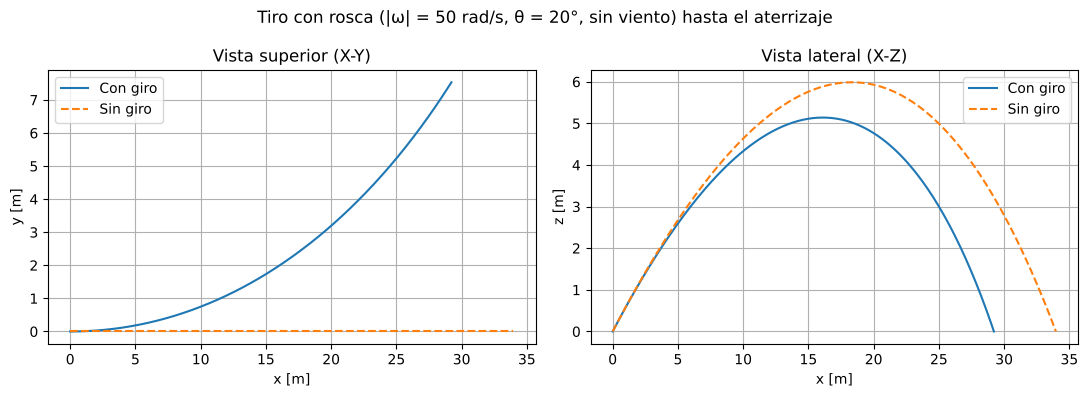

In [4]:
omega_mag_ejemplo = 50.0             # magnitud de la velocidad angular [rad/s]
theta_ejemplo = np.deg2rad(20.0)     # inclinación del eje de rotación
omega_ejemplo = omega_mag_ejemplo * np.array([0.0, np.sin(theta_ejemplo), np.cos(theta_ejemplo)])
ejemplo = volar(omega_ejemplo)

S_inicial = R * omega_mag_ejemplo / np.linalg.norm(v0)
print(f"Parámetro de giro al inicio: S = {S_inicial:.2f}")
print(f"Tiempo de vuelo: {ejemplo['t_vuelo']:.2f} s (sin giro: {sin_giro['t_vuelo']:.2f} s)")
print(f"Alcance: {ejemplo['alcance']:.2f} m (sin giro: {sin_giro['alcance']:.2f} m)")
print(f"Desviación lateral al aterrizar: {ejemplo['desviacion']:.2f} m")
print(f"Altura máxima: {ejemplo['z_max']:.2f} m (sin giro: {sin_giro['z_max']:.2f} m)")

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for vuelo, etiqueta, estilo in [(ejemplo, "Con giro", "-"), (sin_giro, "Sin giro", "--")]:
    x, y, z = vuelo["trayectoria"]
    ejes[0].plot(x, y, estilo, label=etiqueta)
    ejes[1].plot(x, z, estilo, label=etiqueta)

ejes[0].set_xlabel("x [m]")
ejes[0].set_ylabel("y [m]")
ejes[0].set_title("Vista superior (X-Y)")
ejes[1].set_xlabel("x [m]")
ejes[1].set_ylabel("z [m]")
ejes[1].set_title("Vista lateral (X-Z)")
for eje in ejes:
    eje.grid()
    eje.legend()
fig.suptitle("Tiro con rosca (|ω| = 50 rad/s, θ = 20°, sin viento) hasta el aterrizaje")
plt.tight_layout()
plt.show()

**Figura 1.** Trayectoria del tiro con rosca de referencia hasta el aterrizaje, en vista superior y lateral, junto con el mismo tiro sin giro.

## Barridos de parámetros

Cada barrido recorre siete valores de $\vec\omega$, todos con las mismas condiciones iniciales. Los resultados de los seis barridos (dos por escenario de viento) se guardan y se reutilizan en todas las figuras y tablas siguientes.

In [5]:
VIENTOS = {
    "Sin viento": SIN_VIENTO,
    "Viento frontal": np.array([-5.0, 0.0, 0.0]),
    "Viento lateral": np.array([0.0, -5.0, 0.0]),
}

# Barrido en |omega| con el eje inclinado theta = 15° (valores negativos: giro en sentido contrario)
omega_mag_valores = np.array([-30, -20, -10, 0, 10, 20, 30], dtype=float)   # rad/s
theta_fijo = np.deg2rad(15)
eje_fijo = np.array([0.0, np.sin(theta_fijo), np.cos(theta_fijo)])

# Barrido en la inclinación theta del eje, con |omega| = 30 rad/s
omega0_fijo = 30.0
theta_valores = np.array([-30, -20, -10, 0, 10, 20, 30], dtype=float)       # grados


def omega_desde_theta(theta_grados, magnitud=omega0_fijo):
    th = np.deg2rad(theta_grados)
    return magnitud * np.array([0.0, np.sin(th), np.cos(th)])


resultados = {}
filas = []
for nombre_viento, v_fluido in VIENTOS.items():
    barrido_omega = [volar(w * eje_fijo, v_fluido) for w in omega_mag_valores]
    barrido_theta = [volar(omega_desde_theta(th), v_fluido) for th in theta_valores]
    resultados[nombre_viento] = {"omega": barrido_omega, "theta": barrido_theta}
    for w, vuelo in zip(omega_mag_valores, barrido_omega):
        filas.append([nombre_viento, "omega_z", round(w * np.cos(theta_fijo), 1), vuelo["t_vuelo"],
                      vuelo["alcance"], vuelo["desviacion"], vuelo["z_max"]])
    for th, vuelo in zip(theta_valores, barrido_theta):
        filas.append([nombre_viento, "theta", th, vuelo["t_vuelo"],
                      vuelo["alcance"], vuelo["desviacion"], vuelo["z_max"]])

tabla = pd.DataFrame(filas, columns=["viento", "barrido", "valor", "t_vuelo (s)",
                                     "alcance (m)", "desviación (m)", "z_max (m)"])
print(f"Vuelos integrados: {len(tabla)}")

Vuelos integrados: 42


In [6]:
def figura_escenario(nombre_viento, numero):
    '''Trayectorias (vista superior y lateral) de los dos barridos de un escenario de viento.'''
    fig, ejes = plt.subplots(2, 2, figsize=(12, 8.5), sharex=True)
    barridos = [
        ("omega", omega_mag_valores * np.cos(theta_fijo), plt.cm.coolwarm,
         lambda v: f"$\\omega_z$ = {v:+.0f} rad/s"),
        ("theta", theta_valores, plt.cm.viridis, lambda v: f"θ = {v:+.0f}°"),
    ]
    for fila, (clave, valores, mapa, etiqueta) in enumerate(barridos):
        colores = mapa(np.linspace(0.0, 1.0, len(valores)))
        for vuelo, valor, color in zip(resultados[nombre_viento][clave], valores, colores):
            x, y, z = vuelo["trayectoria"]
            ejes[fila, 0].plot(x, y, color=color, label=etiqueta(valor))
            ejes[fila, 1].plot(x, z, color=color, label=etiqueta(valor))
        ejes[fila, 0].set_ylabel("y [m]")
        ejes[fila, 1].set_ylabel("z [m]")
        ejes[fila, 1].legend(fontsize=8, loc="lower center", ncol=2)
    ejes[0, 0].set_title(r"Barrido en $|\omega|$ ($\theta$ = 15°): vista superior")
    ejes[0, 1].set_title(r"Barrido en $|\omega|$ ($\theta$ = 15°): vista lateral")
    ejes[1, 0].set_title(r"Barrido en $\theta$ ($|\omega|$ = 30 rad/s): vista superior")
    ejes[1, 1].set_title(r"Barrido en $\theta$ ($|\omega|$ = 30 rad/s): vista lateral")
    for eje in ejes.ravel():
        eje.grid(alpha=0.4)
    for eje in ejes[1]:
        eje.set_xlabel("x [m]")
    fig.suptitle(f"Figura {numero}: trayectorias hasta el aterrizaje ({nombre_viento.lower()})")
    plt.tight_layout()
    plt.show()

### Sin viento

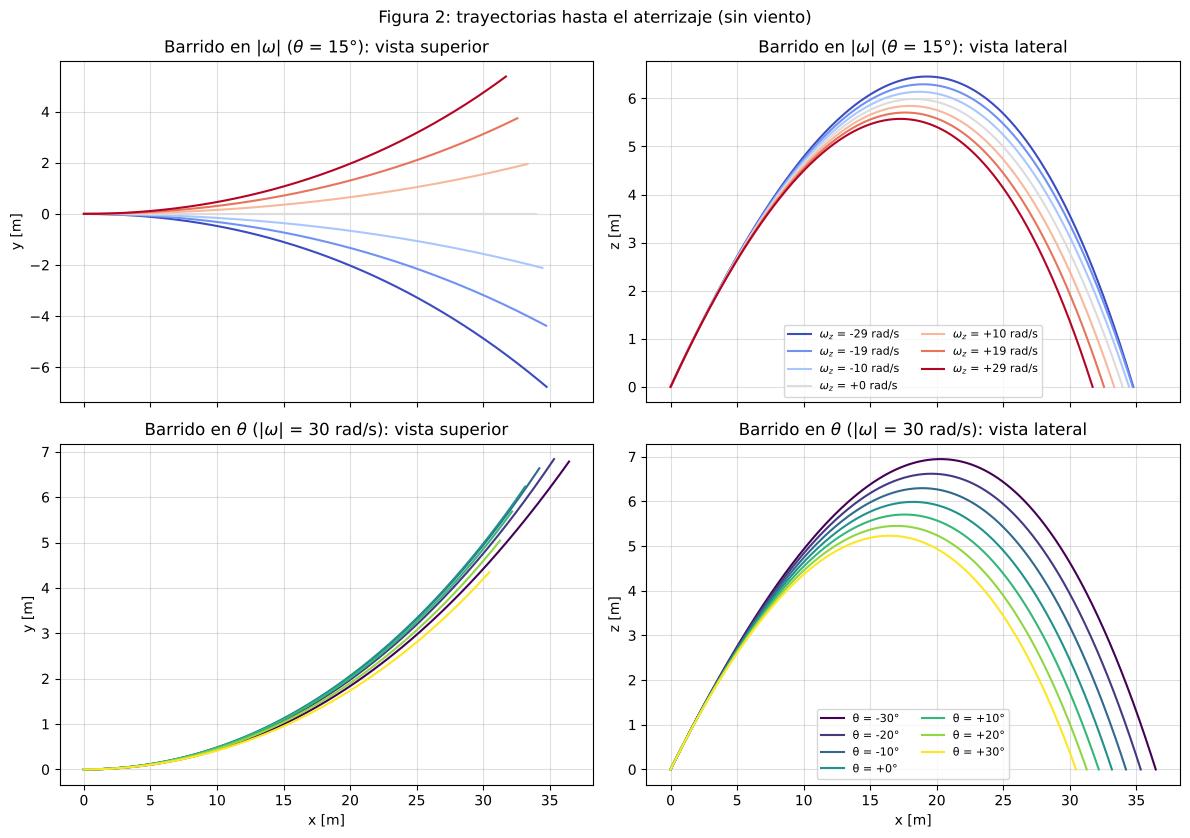

In [7]:
figura_escenario("Sin viento", 2)

**Figura 2.** Trayectorias sin viento: arriba, barrido en la magnitud de la velocidad angular con el eje inclinado $15^\circ$; abajo, barrido en la inclinación del eje con $\lvert\vec\omega\rvert = 30$ rad/s. Cada curva termina en el punto de aterrizaje.

### Viento frontal

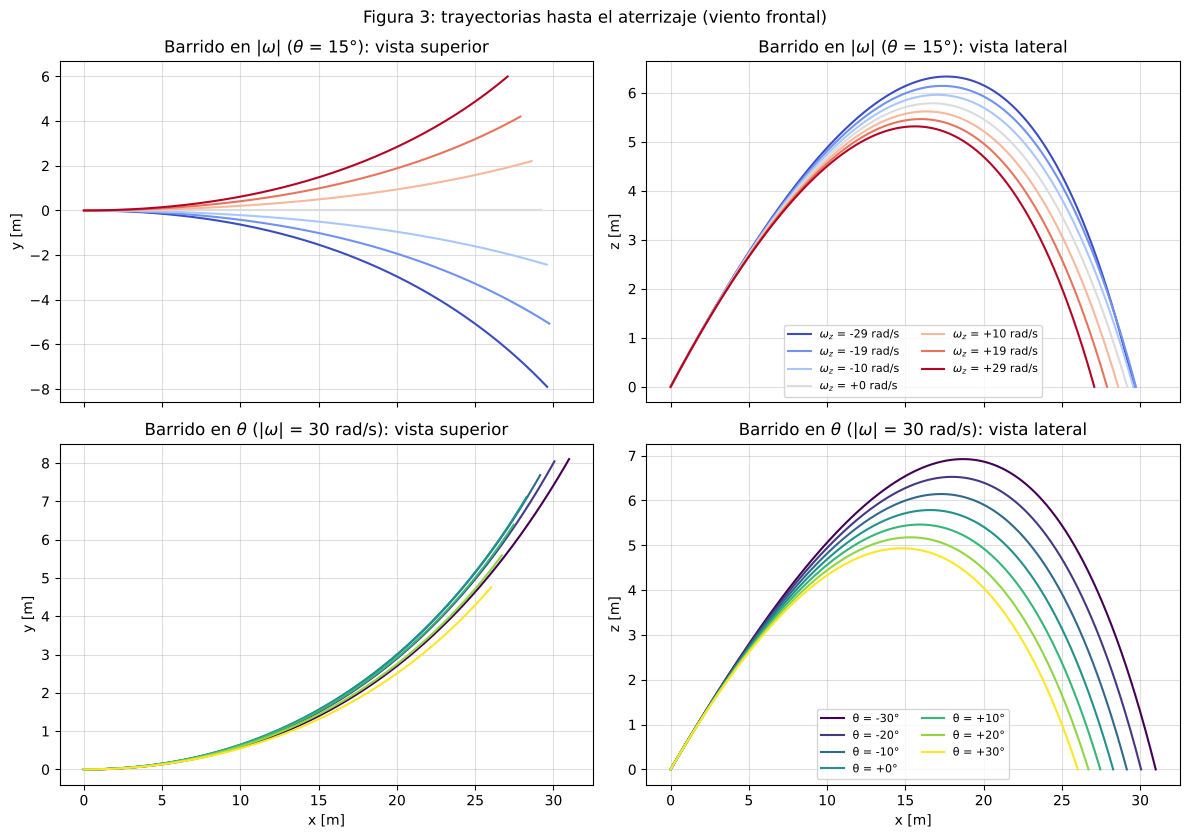

In [8]:
figura_escenario("Viento frontal", 3)

**Figura 3.** Trayectorias con viento frontal de 5 m/s: arriba, barrido en la magnitud de la velocidad angular con el eje inclinado $15^\circ$; abajo, barrido en la inclinación del eje con $\lvert\vec\omega\rvert = 30$ rad/s. Cada curva termina en el punto de aterrizaje.

### Viento lateral

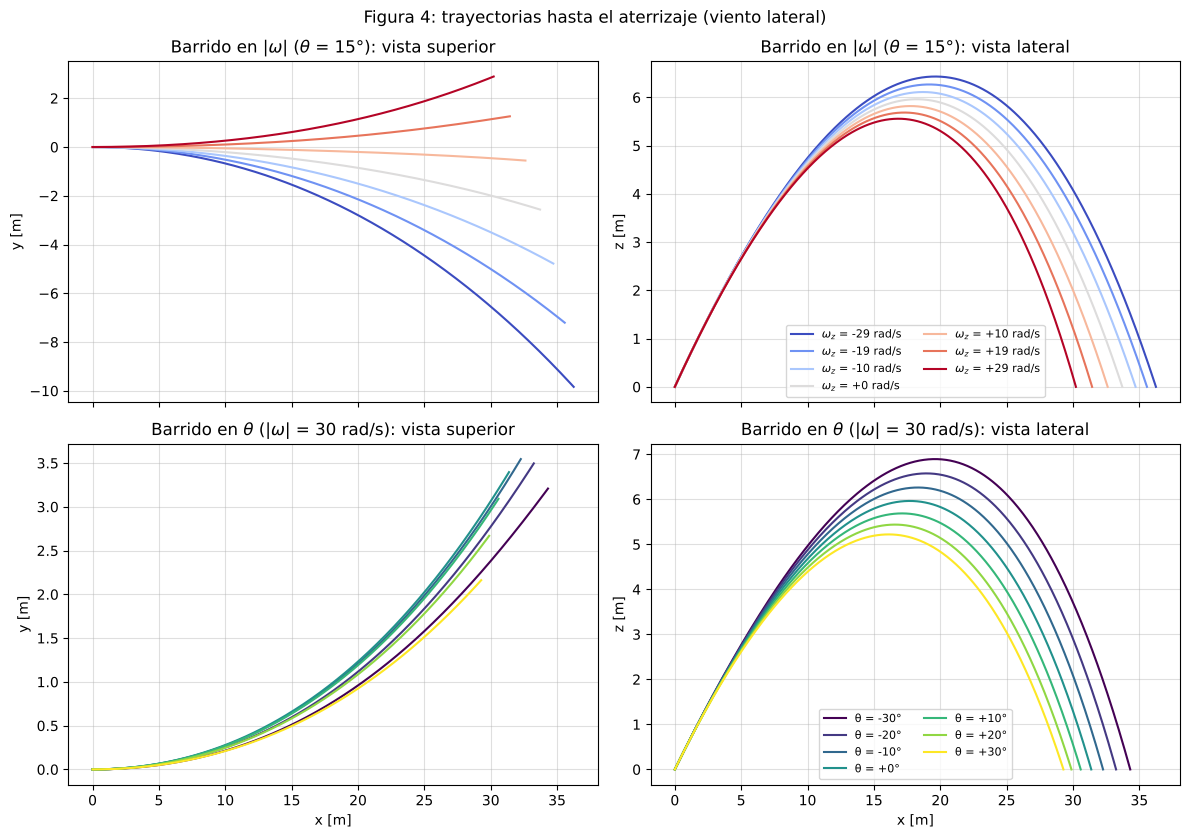

In [9]:
figura_escenario("Viento lateral", 4)

**Figura 4.** Trayectorias con viento lateral de 5 m/s hacia $-y$: arriba, barrido en la magnitud de la velocidad angular con el eje inclinado $15^\circ$; abajo, barrido en la inclinación del eje con $\lvert\vec\omega\rvert = 30$ rad/s. Cada curva termina en el punto de aterrizaje.

## Comparación entre escenarios

La figura siguiente reúne, para los tres escenarios de viento, la desviación lateral en el punto de aterrizaje, la altura máxima y el alcance en función del parámetro barrido. Las tablas recogen la desviación lateral de cada vuelo.

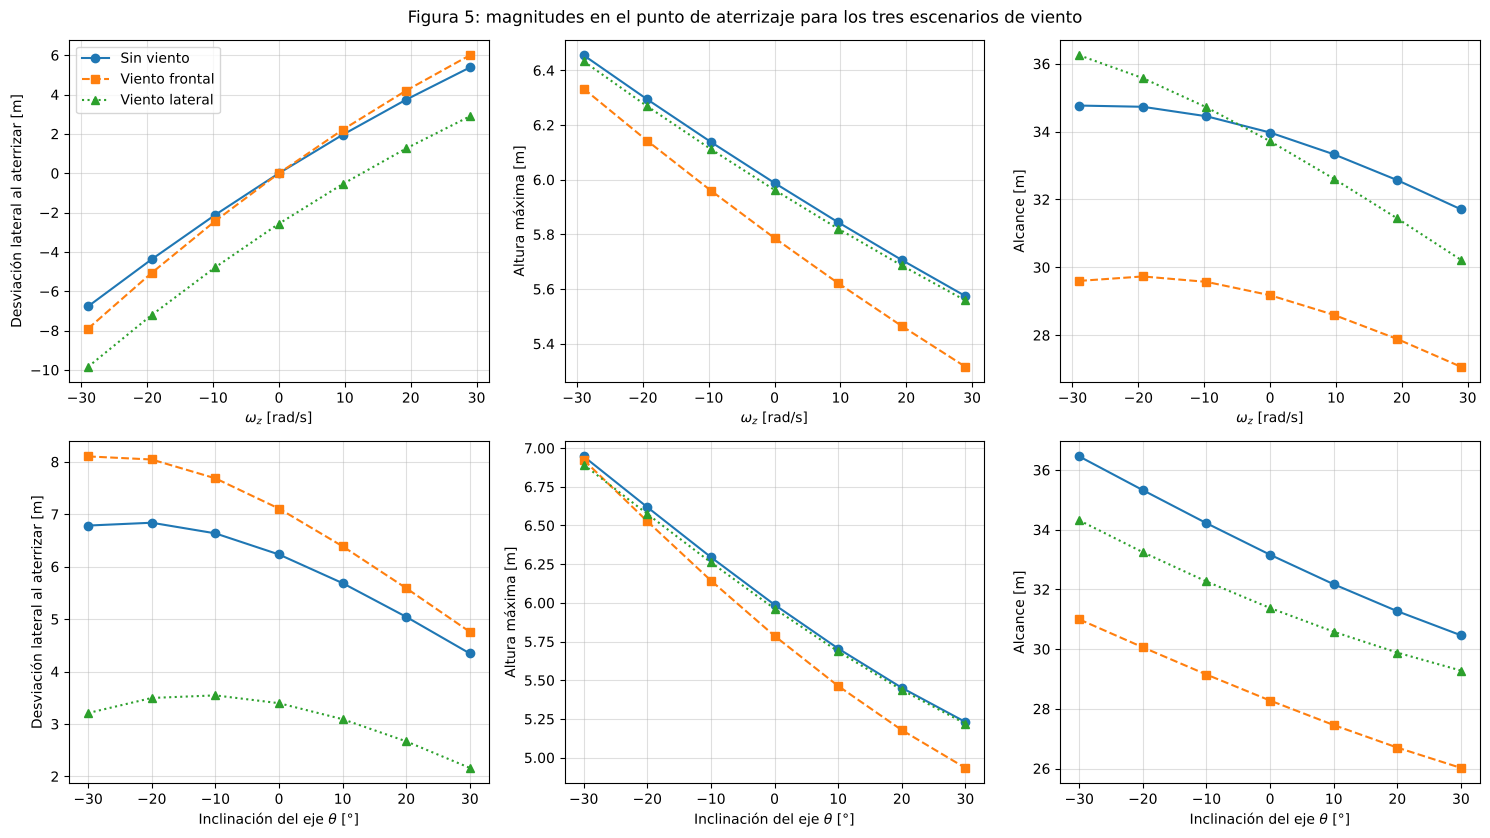


Desviación lateral al aterrizar (m), barrido en ω_z (rad/s):
viento       Sin viento  Viento frontal  Viento lateral
ω_z (rad/s)                                            
-29.0             -6.77           -7.90           -9.84
-19.3             -4.37           -5.06           -7.21
-9.7              -2.11           -2.43           -4.78
 0.0               0.00            0.00           -2.56
 9.7               1.95            2.21           -0.55
 19.3              3.74            4.20            1.26
 29.0              5.37            6.00            2.89

Desviación lateral al aterrizar (m), barrido en θ (°):
viento  Sin viento  Viento frontal  Viento lateral
θ (°)                                             
-30.0         6.78            8.10            3.21
-20.0         6.84            8.04            3.50
-10.0         6.64            7.69            3.55
 0.0          6.23            7.11            3.40
 10.0         5.69            6.39            3.09
 20.0         5.04   

In [10]:
fig, ejes = plt.subplots(2, 3, figsize=(15, 8.5))
magnitudes = [("desviacion", "Desviación lateral al aterrizar [m]"),
              ("z_max", "Altura máxima [m]"),
              ("alcance", "Alcance [m]")]
marcadores = {"Sin viento": "o-", "Viento frontal": "s--", "Viento lateral": "^:"}
for fila, (clave, valores, xlabel) in enumerate([
        ("omega", omega_mag_valores * np.cos(theta_fijo), r"$\omega_z$ [rad/s]"),
        ("theta", theta_valores, r"Inclinación del eje $\theta$ [°]")]):
    for col, (magnitud, ylabel) in enumerate(magnitudes):
        eje = ejes[fila, col]
        for nombre_viento, vuelos in resultados.items():
            eje.plot(valores, [v[magnitud] for v in vuelos[clave]], marcadores[nombre_viento],
                     label=nombre_viento)
        eje.set_xlabel(xlabel)
        eje.set_ylabel(ylabel)
        eje.grid(alpha=0.4)
ejes[0, 0].legend()
fig.suptitle("Figura 5: magnitudes en el punto de aterrizaje para los tres escenarios de viento")
plt.tight_layout()
plt.show()

for barrido, columna in [("omega_z", "ω_z (rad/s)"), ("theta", "θ (°)")]:
    pivote = (tabla[tabla["barrido"] == barrido]
              .pivot(index="valor", columns="viento", values="desviación (m)")
              .rename_axis(columna).round(2))
    print(f"\nDesviación lateral al aterrizar (m), barrido en {columna}:")
    print(pivote.to_string())

**Figura 5.** Desviación lateral en el punto de aterrizaje, altura máxima y alcance en función de la componente vertical de la velocidad angular (arriba) y de la inclinación del eje de rotación (abajo), para los tres escenarios de viento.

## Análisis y conclusiones

**Validación.** En el vacío, el tiempo de vuelo y el alcance numéricos coinciden con los exactos en las nueve cifras decimales mostradas, lo que confirma la integración y la detección del aterrizaje. Con arrastre y sin giro, el alcance se reduce de 48.9 m a 34.0 m (un 31 %) y la altura máxima es de 6.0 m.

**Tiro de referencia (Figura 1).** Con $\lvert\vec\omega\rvert = 50$ rad/s ($S = 0.24$) y el eje inclinado $20^\circ$, el balón se desvía 7.5 m lateralmente en un alcance de 29.2 m. La componente de efecto superior del giro lo empuja además hacia abajo: la altura máxima baja de 6.0 m a 5.1 m y el vuelo dura 1.89 s en lugar de 2.20 s.

**Velocidad angular (Figuras 2 y 5).** La desviación lateral al aterrizar crece casi linealmente con $\omega_z$: sin viento, va de $-6.8$ m a $+5.4$ m para $\omega_z$ entre $-29$ y $+29$ rad/s. La asimetría entre ambos sentidos de giro se debe a la inclinación de $15^\circ$ del eje: cuando $\omega_z < 0$, la componente horizontal del giro es de efecto inferior, sostiene el balón (altura máxima de 6.5 m frente a 5.6 m) y alarga el vuelo (2.37 s frente a 2.05 s), de modo que la fuerza lateral actúa durante más tiempo.

**Inclinación del eje (Figuras 2 y 5).** Con $\lvert\vec\omega\rvert = 30$ rad/s, la componente vertical del giro, responsable de la desviación lateral, disminuye como $\cos\theta$, pero la desviación al aterrizar no es simétrica en $\theta$: sin viento, es de unos 6.8 m para $\theta$ entre $-30^\circ$ y $-20^\circ$ y baja a 4.3 m para $\theta = +30^\circ$. La razón es el tiempo de vuelo: el efecto inferior ($\theta < 0$) lo prolonga hasta 2.55 s, mientras que el efecto superior ($\theta > 0$) lo acorta a 1.92 s. La inclinación del eje decide, sobre todo, qué parte de la fuerza de Magnus actúa en la vertical, lo que cambia la altura máxima (de 6.95 m a 5.23 m), el alcance (de 36.5 m a 30.5 m) y el tiempo de vuelo, y a través de este último también la desviación lateral.

**Viento frontal (Figuras 3 y 5).** Un viento de 5 m/s en contra del avance aumenta la velocidad relativa al aire y, con ella, tanto el arrastre como la fuerza de Magnus. El alcance sin giro cae de 34.0 m a 29.2 m, pero la desviación lateral aumenta: 6.0 m frente a 5.4 m para $\omega_z = +29$ rad/s, y $-7.9$ m frente a $-6.8$ m para $\omega_z = -29$ rad/s. La rosca se nota más aunque el balón llegue menos lejos; por la misma razón, un viento a favor la reduciría.

**Viento lateral (Figuras 4 y 5).** Un viento de 5 m/s hacia $-y$ desplaza el punto de aterrizaje 2.6 m en esa dirección incluso sin giro: es un efecto del arrastre, que actúa a lo largo de la velocidad relativa al aire. Con giro, la desviación es aproximadamente la suma de ese desplazamiento y la desviación sin viento (2.9 m frente a $5.4 - 2.6 = 2.8$ m para $\omega_z = +29$ rad/s). El viento lateral apenas modifica la altura máxima, pero sí el alcance: como $\vec v_{\mathrm{rel}}$ adquiere una componente lateral, el producto $\vec\omega \times \vec v_{\mathrm{rel}}$ tiene una componente a lo largo de $x$, y el alcance pasa de 36.3 m con $\omega_z = -29$ rad/s a 30.2 m con $\omega_z = +29$ rad/s.

**Resumen.** La componente vertical de la velocidad angular determina la desviación lateral; la inclinación del eje decide qué parte de la fuerza de Magnus actúa en la vertical, lo que modifica la altura, el alcance y el tiempo de vuelo, y a través de este último también la desviación; el viento frontal intensifica el efecto Magnus, y el lateral añade una deriva en la dirección del viento debida principalmente al arrastre.

**Limitaciones y trabajo futuro.** Se supuso $\vec\omega$ constante, coeficientes $C_D$ y $k_L$ constantes y un viento uniforme. En un balón real el giro decae lentamente durante el vuelo, $C_D$ cambia con el número de Reynolds en torno a la crisis de arrastre y $C_L$ deja de crecer linealmente con $S$ para giros grandes (Goff y Carré, 2009). Un trabajo futuro podría incorporar estas dependencias, contrastar las trayectorias simuladas con mediciones de vídeo de tiros reales y estudiar el efecto de los parámetros del balón (masa, radio, rugosidad).

## Referencias

### Fuentes académicas

Bray, K., & Kerwin, D. G. (2003). Modelling the flight of a soccer ball in a direct free kick. *Journal of Sports Sciences*, *21*(2), 75–85. https://doi.org/10.1080/0264041031000070994

Briggs, L. J. (1959). Effect of spin and speed on the lateral deflection (curve) of a baseball; and the Magnus effect for smooth spheres. *American Journal of Physics*, *27*(8), 589–596. https://doi.org/10.1119/1.1934921

Dormand, J. R., & Prince, P. J. (1980). A family of embedded Runge-Kutta formulae. *Journal of Computational and Applied Mathematics*, *6*(1), 19–26. https://doi.org/10.1016/0771-050X(80)90013-3

Goff, J. E., & Carré, M. J. (2009). Trajectory analysis of a soccer ball. *American Journal of Physics*, *77*(11), 1020–1027. https://doi.org/10.1119/1.3197187

Goldstein, H., Poole, C. P., & Safko, J. L. (2001). *Classical mechanics* (3rd ed.). Addison-Wesley.

Harris, C. R., Millman, K. J., van der Walt, S. J., Gommers, R., Virtanen, P., Cournapeau, D., Wieser, E., Taylor, J., Berg, S., Smith, N. J., Kern, R., Picus, M., Hoyer, S., van Kerkwijk, M. H., Brett, M., Haldane, A., del Río, J. F., Wiebe, M., Peterson, P., … Oliphant, T. E. (2020). Array programming with NumPy. *Nature*, *585*, 357–362. https://doi.org/10.1038/s41586-020-2649-2

Landau, L. D., y Lifshitz, E. M. (1987). *Fluid mechanics* (2.ª ed., Course of Theoretical Physics, Vol. 6). Pergamon Press.

Magnus, G. (1853). Ueber die Abweichung der Geschosse, und: Ueber eine auffallende Erscheinung bei rotirenden Körpern. *Annalen der Physik*, *164*(1), 1–29. https://doi.org/10.1002/andp.18531640102

Mehta, R. D. (1985). Aerodynamics of sports balls. *Annual Review of Fluid Mechanics*, *17*, 151–189. https://doi.org/10.1146/annurev.fl.17.010185.001055

Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., Burovski, E., Peterson, P., Weckesser, W., Bright, J., van der Walt, S. J., Brett, M., Wilson, J., Millman, K. J., Mayorov, N., Nelson, A. R. J., Jones, E., Kern, R., Larson, E., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods*, *17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2

### Recursos complementarios

Wikipedia. (s. f.). *Efecto Magnus*. Recuperado en 2026, de https://es.wikipedia.org/wiki/Efecto_Magnus